# MercaRAG — RAG multimodal con PostgreSQL + pgvector
Adaptación del **laboratorio pgvector multimodal** al dominio del supermercado (Entrega 1).

El sistema guarda documentos (fichas de producto, políticas, manuales y guías) y fotos de productos en PostgreSQL,
los convierte en vectores, busca por similitud con **pgvector** y le pasa lo encontrado a un LLM (Groq) para que redacte la respuesta.

| Ruta | Consulta | Se compara contra | Modelo | Dim. | Requerimiento |
|---|---|---|---|---|---|
| Texto → Texto | pregunta | chunks (3 estrategias) | MiniLM multilingüe | 384 | RF-06 |
| Texto → Imagen | descripción | fotos del catálogo | CLIP texto multilingüe | 512 | RF-09 |
| Imagen → Imagen | foto | fotos del catálogo | CLIP imagen | 512 | |
| Imagen → Texto | foto | chunks en espacio CLIP | CLIP | 512 | |
| Productos similares | descripción | fichas de producto | MiniLM | 384 | RF-04 |
| Híbrida | descripción + sede + precio | fichas + inventario | MiniLM + SQL | 384 | RF-05 |

**Regla de oro:** solo se comparan vectores del mismo espacio. Un vector de 384 nunca se compara con uno de 512.

El código está en el paquete `mercarag/` (junto a este notebook); aquí se ejecuta paso a paso.

## 1. Importaciones y configuración

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mercarag import config, db, documentos, chunking, carga, busqueda, rag
from mercarag.embeddings import Modelos, abrir_imagen

pd.set_option("display.max_colwidth", 120)
print("Modelo de texto :", config.MODELO_TEXTO)
print("CLIP imagen     :", config.MODELO_CLIP_IMAGEN)
print("CLIP texto      :", config.MODELO_CLIP_TEXTO)
print("LLM             :", config.LLM_MODEL, "| llave Groq:", "sí" if config.GROQ_API_KEY else "no (se omite la generación)")
print("Parámetros de chunking (Entrega 1):")
for estrategia, params in config.PARAMETROS_CHUNKING.items():
    print(f"  {estrategia:10s} {params}")

Modelo de texto : sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
CLIP imagen     : sentence-transformers/clip-ViT-B-32
CLIP texto      : sentence-transformers/clip-ViT-B-32-multilingual-v1
LLM             : openai/gpt-oss-120b | llave Groq: sí
Parámetros de chunking (Entrega 1):
  fijo       {'chunk_size': 512, 'chunk_overlap': 64, 'encoding_name': 'cl100k_base'}
  oraciones  {'max_sentences': 6, 'overlap': 1, 'spacy_model': 'es_core_news_sm'}
  semantico  {'threshold': 0.65, 'thresholds_experimento': [0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7], 'max_tokens': 480, 'min_tokens': 16}


## 2. Conexión a PostgreSQL
`autocommit = True` evita que un error deje la sesión en *current transaction is aborted*; las cargas abren su propia transacción.
`register_vector` permite pasar arreglos de NumPy directamente como parámetros `%s`.

In [2]:
conn = db.get_connection()
with conn.cursor() as cur:
    cur.execute("SELECT version()")
    print(cur.fetchone()[0])
print("pgvector", db.version_pgvector(conn))

# El esquema (schema.sql) y los datos del dominio (sql/02_datos_dominio.sql) los carga Docker al crear la base
with conn.cursor() as cur:
    cur.execute("""SELECT (SELECT count(*) FROM producto), (SELECT count(*) FROM inventario),
                          (SELECT count(*) FROM compra), (SELECT count(*) FROM domicilio)""")
    p, i, c, d = cur.fetchone()
print(f"Productos: {p}  Inventario: {i}  Compras: {c}  Domicilios: {d}")
assert p > 0, "La base no tiene datos: ejecute 'docker compose down -v' y 'docker compose up -d' para recrearla"

PostgreSQL 17.11 (Debian 17.11-1.pgdg12+2) on x86_64-pc-linux-gnu, compiled by gcc (Debian 12.2.0-14+deb12u1) 12.2.0, 64-bit
pgvector 0.8.7
Productos: 1215  Inventario: 5164  Compras: 30000  Domicilios: 20043


## 3. Carga de modelos
La primera vez se descargan (~1,6 GB) y quedan en el volumen `modelos_hf`. Las dimensiones se **calculan** y se comparan con las columnas `VECTOR(n)` del esquema.

In [3]:
modelos = Modelos()
dims = modelos.dimensiones()
print(dims)
assert dims["texto"] == config.DIM_TEXTO, "MiniLM debe dar 384 dimensiones (VECTOR(384))"
assert dims["clip_texto"] == dims["clip_imagen"] == config.DIM_CLIP, "CLIP debe dar 512 dimensiones (VECTOR(512))"

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

/home/estudiante/trabajo/notebooks/mercarag/embeddings.py:58: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  "texto": self.texto.get_sentence_embedding_dimension(),


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

/home/estudiante/trabajo/notebooks/mercarag/embeddings.py:59: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  "clip_texto": self.clip_texto.get_sentence_embedding_dimension(),


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

{'texto': 384, 'clip_texto': 512, 'clip_imagen': 512}


## 4. (Opcional) Reiniciar la capa RAG
Con `REINICIAR_RAG = True` se borran documentos, imágenes, vectores y consultas, **sin tocar** los datos del negocio
(productos, inventario, compras). Útil si cambian los modelos o los parámetros de chunking.

In [4]:
REINICIAR_RAG = False

if REINICIAR_RAG:
    with conn.cursor() as cur:
        cur.execute("""TRUNCATE evaluacion, resultado, query_embeddings, consulta,
                                embeddings_texto_clip, embeddings_texto, embeddings_imagen,
                                imagen_etiqueta, imagen, documento RESTART IDENTITY CASCADE""")
    print("Capa RAG reiniciada")

## 5. Documentos y las tres estrategias de chunking
Los documentos están en `data/documentos/` (Markdown con encabezado de metadatos; también se aceptan `.txt` y `.pdf`).
Cada ficha trae `codigo_barras`, que la enlaza con su producto (`documento.id_producto`): ese es el puente entre el RAG y el negocio.

In [5]:
docs = documentos.cargar_documentos()
print(f"{len(docs)} documentos")
pd.DataFrame(docs)[["codigo_doc", "tipo", "titulo", "codigo_barras"]].groupby("tipo").head(3)

93 documentos


,codigo_doc,tipo,titulo,codigo_barras
0,FICHA_ACEITE_DE_GIRASOL,ficha,Ficha de producto - Aceite de girasol,7700000005267
1,FICHA_AGUA_CON_GAS,ficha,Ficha de producto - Agua con gas,7700000006769
2,FICHA_AGUA_SIN_GAS,ficha,Ficha de producto - Agua sin gas,7700000006165
81,GUIA_CAFE_CALDAS,guia,Guía del café de Caldas,NaN
82,GUIA_ETIQUETADO,guia,Guía para leer el etiquetado nutricional y los alérgenos,NaN
83,GUIA_PUNTOS_VENTA,guia,Guía de puntos de venta y horarios,NaN
85,MAN_CADENA_FRIO,manual,Manual de cadena de frío y manejo de perecederos,NaN
86,MAN_CAJA,manual,Manual de caja y medios de pago,NaN
87,MAN_CONDUCTORES,manual,Manual del conductor de domicilios,NaN
89,POL_DATOS_PERSONALES,politica,Política de tratamiento de datos personales,NaN


Así parte cada estrategia el mismo documento. El **fijo** corta por tokens (puede partir una oración o una palabra),
el de **oraciones** agrupa 6 oraciones completas que se solapan 1, y el **semántico** corta donde cambia el tema.

In [6]:
doc = next(d for d in docs if d["codigo_doc"] == "POL_DOMICILIOS")
for estrategia in config.ESTRATEGIAS:
    chunks, usados = chunking.generar_chunks(doc["contenido_texto"], estrategia, modelos)
    print(f"\n===== {estrategia.upper()} -> {len(chunks)} chunks  {usados}")
    for i, ch in enumerate(chunks[:3]):
        print(f"  [{i}] ({len(ch)} car.) {ch[:160]}...")


===== FIJO -> 2 chunks  {'chunk_size': 512, 'chunk_overlap': 64, 'encoding_name': 'cl100k_base', 'herramienta': 'langchain.TokenTextSplitter'}
  [0] (1922 car.) Política del servicio de domicilios.

Cobertura.
El servicio de domicilios cubre el área urbana de Manizales y el municipio de Villamaría. Cada pedido se despac...
  [1] (1443 car.) alistando en la sede.
En ruta: el pedido salió de la sede con un conductor y un vehículo asignados.
Entregado: el cliente recibió el pedido; se registra la hora...

===== ORACIONES -> 7 chunks  {'max_sentences': 6, 'overlap': 1, 'spacy_model': 'es_core_news_sm', 'herramienta': 'spaCy'}
  [0] (449 car.) Política del servicio de domicilios. Cobertura. El servicio de domicilios cubre el área urbana de Manizales y el municipio de Villamaría. Cada pedido se despach...
  [1] (437 car.) Horarios. Los pedidos se reciben todos los días entre las 7:00 a. m. y las 8:00 p. m. Los pedidos hechos después de las 8:00 p. m. se programan para la primera ...
  [2] (

## 6. Catálogo de fotos
Las fotos van en `data/imagenes/<producto_base>/` (ver `data/imagenes/LEEME.md`). Por cada foto se calcula el SHA-256
(para no duplicarla), el ancho y alto (corrigiendo la orientación EXIF) y la ruta relativa a `data/`.

In [7]:
catalogo = carga.catalogo_imagenes()
print(f"{len(catalogo)} fotos encontradas")
if not catalogo:
    print("⚠ No hay fotos en data/imagenes/. Las rutas con imágenes se omitirán; vea data/imagenes/LEEME.md")
pd.DataFrame(catalogo)[["codigo_img", "ruta_archivo", "codigo_doc", "ancho", "alto", "etiquetas"]].head(10) if catalogo else None

/usr/local/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


116 fotos encontradas


,codigo_img,ruta_archivo,codigo_doc,ancho,alto,etiquetas
0,IMG_ACEITE_DE_GIRASOL_4a94e4a6,imagenes/aceite_de_girasol/297791_1_238.webp,FICHA_ACEITE_DE_GIRASOL,500,500,[aceite de girasol]
1,IMG_ACEITE_DE_GIRASOL_3c0a3e87,imagenes/aceite_de_girasol/D_NQ_NP_642469-MLA116019668102_092026-O.webp,FICHA_ACEITE_DE_GIRASOL,500,500,[aceite de girasol]
2,IMG_ACEITE_DE_GIRASOL_ef0f96a9,imagenes/aceite_de_girasol/canola-girasol-x-1000.jpg,FICHA_ACEITE_DE_GIRASOL,500,500,[aceite de girasol]
3,IMG_ACEITE_DE_GIRASOL_748f0b05,imagenes/aceite_de_girasol/images.jpg,FICHA_ACEITE_DE_GIRASOL,399,501,[aceite de girasol]
4,IMG_AGUA_CON_GAS_cec0a6ae,imagenes/agua_con_gas/Agua-Con-Gas-600-ml-193043_a.webp,FICHA_AGUA_CON_GAS,1000,1000,[agua con gas]
5,IMG_AGUA_CON_GAS_e493924b,imagenes/agua_con_gas/Agua-con-gass.webp,FICHA_AGUA_CON_GAS,1200,1200,[agua con gas]
6,IMG_AGUA_CON_GAS_7900fe3d,imagenes/agua_con_gas/agua-manantial-con-gas-botella-600mlagua-manantial-con-gas-botella-600mlmanantiallicores-medel...,FICHA_AGUA_CON_GAS,810,891,[agua con gas]
7,IMG_AGUA_CON_GAS_37f49a25,imagenes/agua_con_gas/images.jpg,FICHA_AGUA_CON_GAS,333,600,[agua con gas]
8,IMG_AGUA_SIN_GAS_c3547da2,imagenes/agua_sin_gas/59673-1-AGUA-MANANTIAL-FCO-X-600ML.webp,FICHA_AGUA_SIN_GAS,1000,1000,[agua sin gas]
9,IMG_AGUA_SIN_GAS_3db0f1d5,imagenes/agua_sin_gas/AGUA-PURA-SIN-GAS-1375498_a.webp,FICHA_AGUA_SIN_GAS,507,1000,[agua sin gas]


## 7. Carga transaccional (idempotente)
`INSERT ... ON CONFLICT ... DO UPDATE ... RETURNING id`: se puede ejecutar varias veces sin duplicar.
Se guardan los chunks de **las tres estrategias** en `embeddings_texto` (columna `estrategia_chunking`), con su vector MiniLM
y su vector CLIP de texto (`embeddings_texto_clip`, para la ruta imagen → texto). Si algo falla: `ROLLBACK`.

In [8]:
resumen_docs = carga.cargar_documentos(conn, docs, modelos)
print(resumen_docs)
if catalogo:
    print(carga.cargar_imagenes(conn, catalogo, modelos))

Batches:   0%|          | 0/44 [00:00<?, ?it/s]

Batches:   0%|          | 0/44 [00:00<?, ?it/s]

{'documentos': 93, 'chunks': 1406, 'por_estrategia': {'fijo': 104, 'oraciones': 305, 'semantico': 997}, 'segundos': 161.43}


/usr/local/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


{'imagenes': 116, 'segundos': 11.98}


## 8. Verificación de integridad
`LEFT JOIN ... IS NULL`: ningún documento sin chunks, ningún chunk ni imagen sin vector.

In [9]:
integridad = carga.verificar_integridad(conn)
print(integridad)
assert integridad["docs_sin_chunks"] == 0
assert integridad["chunks_sin_vector_clip"] == 0
assert integridad["imagenes_sin_vector"] == 0
print("Integridad OK")

{'documentos': 93, 'chunks': 1406, 'imagenes': 116, 'docs_sin_chunks': 0, 'chunks_sin_vector_clip': 0, 'imagenes_sin_vector': 0}
Integridad OK


## 9. Índices vectoriales HNSW
Hay un índice HNSW **parcial por estrategia** (`WHERE estrategia_chunking = ...`), uno para imágenes y uno para los chunks en espacio CLIP.
El operador del índice (`vector_cosine_ops`) debe coincidir con el de la consulta (`<=>`). Con pocas filas PostgreSQL prefiere `Seq Scan`,
así que para ver el índice se desactiva temporalmente.

In [10]:
print(pd.DataFrame(db.consultar(conn, """SELECT indexname, tablename FROM pg_indexes
                                       WHERE indexdef ILIKE '%hnsw%' ORDER BY indexname""", vectorial=False)))

q = modelos.embed_texto(["horario de domicilios"])[0]
with conn.cursor() as cur:
    cur.execute("SET enable_seqscan = off")
    cur.execute("""EXPLAIN ANALYZE
                   SELECT id_embedding FROM embeddings_texto
                   WHERE estrategia_chunking = 'semantico'
                   ORDER BY vector_embedding <=> %s LIMIT 5""", (q,))
    print("\n".join(f[0] for f in cur.fetchall()))
    cur.execute("SET enable_seqscan = on")

                      indexname              tablename
0           idx_emb_imagen_hnsw      embeddings_imagen
1       idx_emb_texto_clip_hnsw  embeddings_texto_clip
2       idx_emb_texto_hnsw_fijo       embeddings_texto
3  idx_emb_texto_hnsw_oraciones       embeddings_texto
4  idx_emb_texto_hnsw_semantico       embeddings_texto
Limit  (cost=481.83..494.58 rows=5 width=12) (actual time=0.233..0.245 rows=5 loops=1)
  ->  Index Scan using idx_emb_texto_hnsw_semantico on embeddings_texto  (cost=481.83..3023.94 rows=997 width=12) (actual time=0.232..0.243 rows=5 loops=1)
        Order By: (vector_embedding <=> '[0.036367018,0.0073438953,-0.006540217,0.045947142,0.03010623,-0.031806175,-0.10779625,-0.06750018,0.010872802,0.013607657,-0.022331746,0.030009974,-0.044212606,0.018087199,-0.013994813,-0.052650318,0.015728809,0.0024378346,0.071676984,0.020248828,0.013514369,0.017457094,-0.031504557,0.016964383,0.116169006,0.03775116,0.08467185,0.013105255,-0.058940716,-0.025156358,0.014323052,-0.04

## 10. Rutas de búsqueda
### 10.1 Texto → Texto (la misma pregunta con cada estrategia)

In [11]:
pregunta = "¿Hasta qué hora puedo pedir un domicilio un domingo?"
for estrategia in config.ESTRATEGIAS:
    print(f"\n--- {estrategia}")
    display(busqueda.buscar_texto_texto(conn, modelos, pregunta, estrategia=estrategia, k=3)
            [["codigo_doc", "chunk_id", "score", "contenido_chunk"]])


--- fijo


,codigo_doc,chunk_id,score,contenido_chunk
0,GUIA_PUNTOS_VENTA,1,0.4454,"7:00 a. m. a 9:00 p. m. Atiende los domicilios de La Enea, Bosques del Norte y Villamaría, y tiene la sección más gr..."
1,POL_DEVOLUCIONES,2,0.2765,"sanducheras y cafeteras, tienen la garantía legal que exige el Estatuto del Consumidor (Ley 1480 de 2011). La solici..."
2,FICHA_AREPA_DE_MAIZ_BLANCO,0,0.2103,"Ficha de producto: Arepa de maíz blanco.\n\nDescripción.\nArepas redondas y delgadas de maíz blanco, listas para asa..."



--- oraciones


,codigo_doc,chunk_id,score,contenido_chunk
0,POL_DOMICILIOS,1,0.5748,Horarios. Los pedidos se reciben todos los días entre las 7:00 a. m. y las 8:00 p. m. Los pedidos hechos después de ...
1,POL_DOMICILIOS,3,0.5602,"En días de lluvia fuerte, que en Manizales son frecuentes en abril, mayo, octubre y noviembre, el tiempo puede aumen..."
2,GUIA_PUNTOS_VENTA,1,0.5518,"En la calle 11 # 9-40, cerca del Monumento a los Colonizadores. Horario de lunes a domingo de 7:00 a. m. a 8:00 p. m..."



--- semantico


,codigo_doc,chunk_id,score,contenido_chunk
0,POL_DOMICILIOS,4,0.7137,Los domingos y festivos el último pedido se recibe a las 6:00 p. m.
1,GUIA_PUNTOS_VENTA,6,0.6653,"Horario de lunes a sábado de 7:00 a. m. a 10:00 p. m., la sede que cierra más tarde, y domingos de 8:00 a. m. a 8:00..."
2,POL_DOMICILIOS,3,0.5965,Horarios. Los pedidos se reciben todos los días entre las 7:00 a. m. y las 8:00 p. m. Los pedidos hechos después de ...


Búsqueda con filtro relacional (solo manuales): el `WHERE` y el `ORDER BY <=>` van en el mismo SQL.

In [12]:
busqueda.buscar_texto_texto(conn, modelos, "temperatura de los lácteos", estrategia="oraciones", k=3, tipo="manual")

,id_embedding,id_doc,codigo_doc,titulo,tipo,chunk_id,estrategia,contenido_chunk,score
0,11481,86,MAN_CADENA_FRIO,Manual de cadena de frío y manejo de perecederos,manual,1,oraciones,"Los lácteos, huevos refrigerados, embutidos y carnes frescas se conservan entre 0 °C y 4 °C. Las frutas y verduras d...",0.6551
1,11482,86,MAN_CADENA_FRIO,Manual de cadena de frío y manejo de perecederos,manual,2,oraciones,"Al llegar un camión del proveedor, el auxiliar mide la temperatura del producto con un termómetro de punzón o infrar...",0.6390
2,11480,86,MAN_CADENA_FRIO,Manual de cadena de frío y manejo de perecederos,manual,0,oraciones,"Manual de cadena de frío y manejo de perecederos. Objetivo. Este manual describe cómo recibir, almacenar, exhibir y ...",0.5347


### 10.2 RF-04 — Productos similares a una descripción

In [13]:
busqueda.productos_similares(conn, modelos, "algo dulce para untar en galletas", k=8)

,producto_base,producto,marca,categoria,precio,score
0,Tostadas de pan,Tostadas de pan Ramo 150 g,Ramo,Panadería,4200.00,0.7398
1,Tostadas de pan,Tostadas de pan Santa Clara 150 g,Santa Clara,Panadería,4600.00,0.7398
2,Tostadas de pan,Tostadas de pan Comapan 150 g,Comapan,Panadería,4900.00,0.7398
3,Tostadas de pan,Tostadas de pan El Trigal 150 g,El Trigal,Panadería,5150.00,0.7398
4,Tostadas de pan,Tostadas de pan Bimbo 150 g,Bimbo,Panadería,5350.00,0.7398
5,Tostadas de pan,Tostadas de pan Santa Clara 250 g,Santa Clara,Panadería,8100.00,0.7398
6,Tostadas de pan,Tostadas de pan Ramo 250 g,Ramo,Panadería,8300.00,0.7398
7,Tostadas de pan,Tostadas de pan Comapan 250 g,Comapan,Panadería,8900.00,0.7398


### 10.3 RF-05 — Búsqueda híbrida
Descripción en lenguaje natural + disponible (`stock > 0`) en una sede + precio máximo (+ promoción vigente opcional).

In [14]:
busqueda.buscar_productos_hibrida(conn, modelos, "café para preparar en greca",
                                  sede="MercaRAG Chipre", precio_max=20000, k=8)

,producto,marca,precio,sede,stock,promocion,score
0,Café molido tostado Corona 250 g,Corona,10650.00,MercaRAG Chipre,28,Café de Caldas a mitad de precio en la segunda unidad,0.6220
1,Café molido tostado Águila Roja 250 g,Águila Roja,11500.00,MercaRAG Chipre,91,Café de Caldas a mitad de precio en la segunda unidad,0.6220
2,Café molido tostado Juan Valdez 250 g,Juan Valdez,13100.00,MercaRAG Chipre,58,Café de Caldas a mitad de precio en la segunda unidad,0.6220
3,Café molido tostado Corona 500 g,Corona,19550.00,MercaRAG Chipre,96,Café de Caldas a mitad de precio en la segunda unidad,0.6220
4,Café soluble Águila Roja 50 g,Águila Roja,9400.00,MercaRAG Chipre,75,Café de Caldas a mitad de precio en la segunda unidad,0.6089
5,Café soluble Sello Rojo 50 g,Sello Rojo,9500.00,MercaRAG Chipre,7,Café de Caldas a mitad de precio en la segunda unidad,0.6089
6,Café soluble Luker 50 g,Luker,9900.00,MercaRAG Chipre,85,Café de Caldas a mitad de precio en la segunda unidad,0.6089
7,Café soluble Juan Valdez 50 g,Juan Valdez,10850.00,MercaRAG Chipre,31,Café de Caldas a mitad de precio en la segunda unidad,0.6089


In [15]:
busqueda.buscar_productos_hibrida(conn, modelos, "comida para mi perro", solo_promocion=True, k=5)

,producto,marca,precio,sede,stock,promocion,score
0,Alimento seco para perro adulto Whiskas 2 kg,Whiskas,29850.00,MercaRAG La Enea,33,Mascotas felices,0.7595
1,Alimento seco para perro adulto Whiskas 2 kg,Whiskas,29850.00,MercaRAG Chipre,120,Mascotas felices,0.7595
2,Alimento seco para perro adulto Whiskas 2 kg,Whiskas,29850.00,MercaRAG Milán,97,Mascotas felices,0.7595
3,Alimento seco para perro adulto Whiskas 2 kg,Whiskas,29850.00,MercaRAG Centro,37,Mascotas felices,0.7595
4,Alimento seco para perro adulto Chunky 2 kg,Chunky,30700.00,MercaRAG Milán,106,Mascotas felices,0.7595


### 10.4 RF-09 — Texto → Imagen
Con CLIP los scores texto→imagen suelen estar entre 0,15 y 0,35: importa el **orden**, no el valor absoluto.

,id_img,codigo_img,ruta_archivo,descripcion,producto,categoria,score
0,107,IMG_BANANO_CRIOLLO_fb7682a4,imagenes/banano_criollo/images (3).jpg,banano criollo,Banano criollo Huerta Caldense 500 g,Frutas y verduras,0.2726
1,32,IMG_AGUACATE_HASS_55101e9d,imagenes/aguacate_hass/images.jpg,aguacate hass,Aguacate Hass Huerta Caldense 1 und,Frutas y verduras,0.2699
2,30,IMG_AGUACATE_HASS_23144f2a,imagenes/aguacate_hass/images (1).jpg,aguacate hass,Aguacate Hass Huerta Caldense 1 und,Frutas y verduras,0.2687
3,31,IMG_AGUACATE_HASS_8b12428b,imagenes/aguacate_hass/images (2).jpg,aguacate hass,Aguacate Hass Huerta Caldense 1 und,Frutas y verduras,0.2674


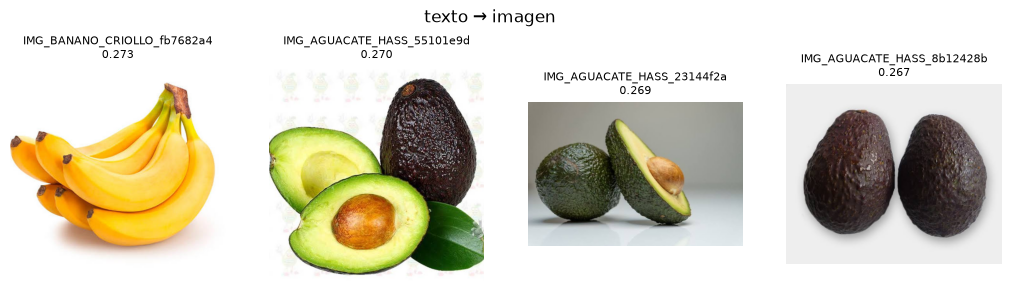

In [16]:
def mostrar_fotos(df, titulo=""):
    if df is None or df.empty:
        print("Sin resultados (¿hay fotos en data/imagenes/?)")
        return
    fig, ejes = plt.subplots(1, len(df), figsize=(3.2 * len(df), 3.4))
    ejes = np.atleast_1d(ejes)
    for eje, fila in zip(ejes, df.itertuples()):
        eje.imshow(abrir_imagen(config.DATA_DIR / fila.ruta_archivo))
        eje.set_title(f"{fila.codigo_img}\n{fila.score:.3f}", fontsize=8)
        eje.axis("off")
    fig.suptitle(titulo)
    plt.show()

res_img = busqueda.buscar_texto_imagen(conn, modelos, "Fruta verde ", k=4)
display(res_img)
mostrar_fotos(res_img, "texto → imagen")

### 10.5 Imagen → Imagen e Imagen → Texto
Con una foto de `data/consultas/` (que no está en la base).

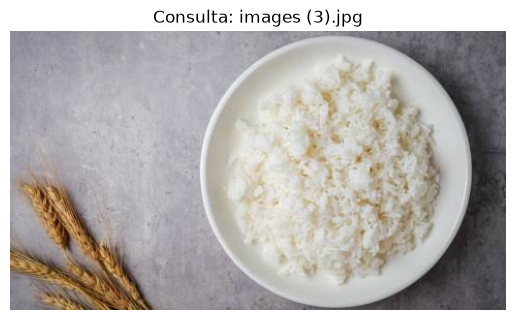

,id_img,codigo_img,ruta_archivo,producto,score
0,16,IMG_ARROZ_BLANCO_40e91e42,imagenes/arroz_blanco/images.jpg,Arroz blanco Diana 500 g,0.8870
1,15,IMG_ARROZ_BLANCO_bccc8f14,imagenes/arroz_blanco/images (2).jpg,Arroz blanco Diana 500 g,0.8626
2,47,IMG_AREPA_DE_MAIZ_BLANCO_0e799b62,imagenes/arepa_de_maiz_blanco/images (3).jpg,Arepa de maíz blanco Bimbo x5,0.7516
3,45,IMG_AREPA_DE_MAIZ_BLANCO_2222d4e7,imagenes/arepa_de_maiz_blanco/images (1).jpg,Arepa de maíz blanco Bimbo x5,0.7504


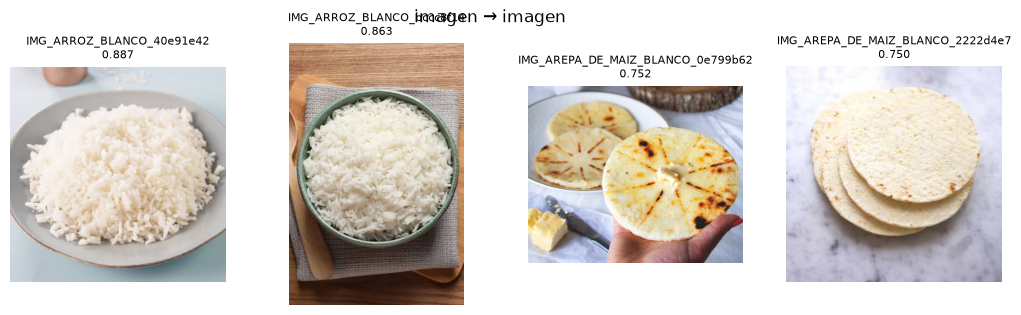

,id_embedding,codigo_doc,titulo,contenido_chunk,score
0,10388,FICHA_AREPA_DE_MAIZ_BLANCO,Ficha de producto - Arepa de maíz blanco,"Arepas redondas y delgadas de maíz blanco, listas para asar y acompañar con queso y mantequilla.",0.3064
1,10809,FICHA_HARINA_DE_MAIZ_PRECOCIDA,Ficha de producto - Harina de maíz precocida,Harina de maíz blanco precocida para preparar arepas en minutos.,0.3052
2,10581,FICHA_CEBOLLA_CABEZONA_BLANCA,Ficha de producto - Cebolla cabezona blanca,"Cebolla blanca de sabor intenso, indispensable para guisos, hogao y sofritos.",0.3045
3,10445,FICHA_AZUCAR_BLANCA,Ficha de producto - Azúcar blanca,"Azúcar refinada de grano fino para bebidas, postres y repostería.",0.3034
4,11466,GUIA_RECETAS,Recetas típicas con productos del supermercado,"Sirva con arroz blanco, chorizo, aguacate y arepa.",0.3028


In [17]:
fotos_consulta = sorted(p for p in config.CONSULTAS_DIR.glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"})
if fotos_consulta and catalogo:
    foto = fotos_consulta[0]
    plt.imshow(abrir_imagen(foto)); plt.axis("off"); plt.title(f"Consulta: {foto.name}"); plt.show()
    res = busqueda.buscar_imagen_imagen(conn, modelos, foto, k=4)
    display(res); mostrar_fotos(res, "imagen → imagen")
    display(busqueda.buscar_imagen_texto(conn, modelos, foto, k=5))
else:
    print("Agregue fotos en data/imagenes/ y al menos una en data/consultas/ para probar estas rutas")

## 11. RAG — respuesta en lenguaje natural (RF-06)
El LLM solo lee texto: los chunks recuperados (y los metadatos de las fotos) se convierten en un bloque de contexto.
El *system prompt* obliga a responder solo con ese contexto. Sin `GROQ_API_KEY` la respuesta es `None` y lo demás sigue funcionando.

> Si Groq responde `404 model_not_found`, cambie `LLM_MODEL` en `.env` por un modelo vigente de console.groq.com/docs/models y ejecute `docker compose up -d`.

In [18]:
salida = rag.preguntar(conn, modelos, "¿Cuánto cuesta el domicilio y cuánto se demora?", estrategia="semantico", k=4)
print(salida["contexto"][:1500])
print("\nRESPUESTA:\n", salida["respuesta"])
print(f"\nRecuperación: {salida['tiempo_recuperacion_ms']} ms | Total: {salida['tiempo_total_ms']} ms | id_consulta = {salida['id_consulta']}")

[1] Documento: POL_DOMICILIOS - Política del servicio de domicilios (score 0.602)
El domicilio cuesta 4.500 pesos para pedidos entre 30.000 y 99.999 pesos, y es gratis para pedidos de 100.000 pesos o más.

[2] Documento: POL_DOMICILIOS - Política del servicio de domicilios (score 0.472)
Costos y pedido mínimo. El pedido mínimo es de 30.000 pesos.

[3] Documento: POL_DOMICILIOS - Política del servicio de domicilios (score 0.452)
Los clientes que compran más de cuatro veces al mes acceden al plan de domicilio gratis sin importar el valor del pedido.

[4] Documento: POL_DOMICILIOS - Política del servicio de domicilios (score 0.452)
Para Villamaría y los barrios de la periferia, como La Enea alta y Bosques del Norte, se cobra un recargo de 2.000 pesos.

Imágenes relacionadas:
- Foto IMG_ARENA_PARA_GATO_312bbef2: arena para gato; producto: Arena para gato Dog Chow 4 kg; categoría: Mascotas; archivo imagenes/arena_para_gato/images.jpg (score 0.225)
- Foto IMG_BANANO_CRIOLLO_40920b76: banano 

In [19]:
def preguntar(texto, estrategia="semantico"):
    s = rag.preguntar(conn, modelos, texto, estrategia=estrategia)
    print(s["respuesta"] or s["contexto"][:800])
    return s

_ = preguntar("¿Qué hago si me llega un producto vencido en el domicilio?")

No tengo esa información.


## 12. Trazabilidad
Cada consulta queda en `consulta`, su vector en `query_embeddings` y cada resultado con su ranking y score en `resultado`.

In [20]:
rag.historial(conn, n=3)

,id_consulta,fecha,email,tipo_consulta,estrategia,pregunta,ranking,recurso,score,tiempo_recuperacion_ms,tiempo_total_ms,respuesta
0,177,2026-11-19 22:37:24.407624,empleado1@mercarag.co,rag,semantico,¿Qué hago si me llega un producto vencido en el domicilio?,1,FICHA_CARNE_MOLIDA_DE_RES,0.6671,80.20,835.66,No tengo esa información.
1,177,2026-11-19 22:37:24.407624,empleado1@mercarag.co,rag,semantico,¿Qué hago si me llega un producto vencido en el domicilio?,2,FICHA_PAPA_PASTUSA,0.6496,80.20,835.66,No tengo esa información.
2,177,2026-11-19 22:37:24.407624,empleado1@mercarag.co,rag,semantico,¿Qué hago si me llega un producto vencido en el domicilio?,3,FICHA_MANI_SALADO,0.6441,80.20,835.66,No tengo esa información.
3,177,2026-11-19 22:37:24.407624,empleado1@mercarag.co,rag,semantico,¿Qué hago si me llega un producto vencido en el domicilio?,4,FICHA_HELADO_DE_VAINILLA,0.6432,80.20,835.66,No tengo esa información.
4,177,2026-11-19 22:37:24.407624,empleado1@mercarag.co,rag,semantico,¿Qué hago si me llega un producto vencido en el domicilio?,5,FICHA_PONQUE_DE_VAINILLA,0.6401,80.20,835.66,No tengo esa información.
5,177,2026-11-19 22:37:24.407624,empleado1@mercarag.co,rag,semantico,¿Qué hago si me llega un producto vencido en el domicilio?,6,IMG_BLANQUEADOR_35829d6f,0.2416,80.20,835.66,No tengo esa información.
6,177,2026-11-19 22:37:24.407624,empleado1@mercarag.co,rag,semantico,¿Qué hago si me llega un producto vencido en el domicilio?,7,IMG_CREMA_DENTAL_aae8bf41,0.2398,80.20,835.66,No tengo esa información.
7,177,2026-11-19 22:37:24.407624,empleado1@mercarag.co,rag,semantico,¿Qué hago si me llega un producto vencido en el domicilio?,8,IMG_ARENA_PARA_GATO_312bbef2,0.2387,80.20,835.66,No tengo esa información.
8,176,2026-11-19 22:37:23.559063,empleado1@mercarag.co,rag,semantico,¿Cuánto cuesta el domicilio y cuánto se demora?,1,POL_DOMICILIOS,0.6023,72.17,2052.57,"El domicilio cuesta 4 500 pesos para pedidos entre 30 000 y 99 999 pesos, y es g"
9,176,2026-11-19 22:37:23.559063,empleado1@mercarag.co,rag,semantico,¿Cuánto cuesta el domicilio y cuánto se demora?,2,POL_DOMICILIOS,0.4718,72.17,2052.57,"El domicilio cuesta 4 500 pesos para pedidos entre 30 000 y 99 999 pesos, y es g"


## 13. Consultas SQL clásicas (RF-02, RF-03, RF-08)
El resto está en `sql/03_consultas_clasicas.sql`.

In [21]:
def sql(q, params=None):
    return pd.DataFrame(db.consultar(conn, q, params, vectorial=False))

# RF-02: existencias de un producto en una sede
display(sql("""SELECT pv.nombre AS sede, p.nombre, i.stock, i.stock_minimo
               FROM inventario i JOIN producto p USING (id_producto) JOIN punto_venta pv USING (id_punto_venta)
               WHERE p.nombre ILIKE %s AND pv.nombre = %s""", ("Leche deslactosada%", "MercaRAG Milán")))

# RF-03: estado de los domicilios de un cliente
display(sql("""SELECT d.id_domicilio, c.fecha, d.estado, d.hora_entrega, v.placa
               FROM domicilio d JOIN compra c USING (id_compra) JOIN cliente cl USING (id_cliente)
               LEFT JOIN vehiculo v ON v.id_vehiculo = d.id_vehiculo
               WHERE cl.documento = %s ORDER BY c.fecha DESC""", ("30000070",)))

# RF-08: métricas de las consultas registradas
display(sql("""SELECT tipo_consulta, estrategia_chunking, count(*) AS consultas,
                      round(avg(tiempo_recuperacion_ms), 1) AS recuperacion_ms, round(avg(tiempo_total_ms), 1) AS total_ms
               FROM consulta GROUP BY 1, 2 ORDER BY 1, 2"""))

,sede,nombre,stock,stock_minimo
0,MercaRAG Milán,Leche deslactosada Alpina 900 ml,117,16
1,MercaRAG Milán,"Leche deslactosada Alpina 1,1 L",34,9
2,MercaRAG Milán,"Leche deslactosada Alpina bolsa x6 1,1 L",45,17
3,MercaRAG Milán,Leche deslactosada Colanta 900 ml,92,18
4,MercaRAG Milán,"Leche deslactosada Colanta 1,1 L",9,13
5,MercaRAG Milán,"Leche deslactosada Colanta bolsa x6 1,1 L",33,14
6,MercaRAG Milán,Leche deslactosada Alquería 900 ml,12,11
7,MercaRAG Milán,"Leche deslactosada Alquería 1,1 L",84,15
8,MercaRAG Milán,"Leche deslactosada Alquería bolsa x6 1,1 L",9,15
9,MercaRAG Milán,Leche deslactosada La Mejor 900 ml,102,18


,id_domicilio,fecha,estado,hora_entrega,placa
0,4379,2026-10-18 23:45:24.725514,entregado,2026-10-19 01:08:47.196826,MZL04D
1,1953,2026-07-11 23:40:23.643187,entregado,2026-07-12 00:20:49.290758,MZL08H
2,16790,2026-06-17 23:53:48.087206,entregado,2026-06-18 00:42:16.092598,MZL10J
3,12265,2026-05-01 14:51:01.234548,entregado,2026-05-01 16:14:46.484343,MZL02B


,tipo_consulta,estrategia_chunking,consultas,recuperacion_ms,total_ms
0,rag,semantico,15,257.7,1131.8
1,texto_texto,fijo,54,2.9,2.9
2,texto_texto,oraciones,54,2.5,2.5
3,texto_texto,semantico,54,4.7,4.7


In [22]:
conn.close()

In [23]:
from mercarag import db, busqueda, rag
from mercarag.embeddings import Modelos
conn = db.get_connection()
modelos = Modelos()

salida = rag.preguntar(conn, modelos, "¿Qué es el arroz?")
print(salida["respuesta"])    
print(salida["contexto"])     


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

No tengo esa información.
[1] Documento: GUIA_RECETAS - Recetas típicas con productos del supermercado (score 0.601)
Sirva con arroz blanco, chorizo, aguacate y arepa.

[2] Documento: MAN_INVENTARIO - Manual de control de inventario y reposición (score 0.432)
Un producto con alta rotación, como el arroz, la leche o el banano, necesita reposición frecuente y pedidos pequeños.

[3] Documento: FICHA_HARINA_DE_MAIZ_PRECOCIDA - Ficha de producto - Harina de maíz precocida (score 0.419)
En MercaRAG se encuentra en la sección de granos y abarrotes.

[4] Documento: FICHA_YOGUR_DE_FRESA - Ficha de producto - Yogur de fresa (score 0.417)
En MercaRAG se encuentra en la sección de lácteos y huevos.

[5] Documento: FICHA_SAL_REFINADA_YODADA - Ficha de producto - Sal refinada yodada (score 0.414)
En MercaRAG se encuentra en la sección de granos y abarrotes.

Imágenes relacionadas:
- Foto IMG_ARROZ_BLANCO_bccc8f14: arroz blanco; producto: Arroz blanco Diana 500 g; categoría: Granos y abarrotes; archi